# Clustering - Ejemplo USArrest
---

In [2]:
# Cargar librerías
library(readr)       # Leer archivos csv
library(magrittr)    # Operador pipe %>%
library(tibble)      # Mejor formato de datos
library(dendextend)  # Funciones para dendrogramas
library(factoextra)  # Visualización de clusters
library(dplyr)
library(knitr)
library(tidyr) 
library(cluster)     # Métodos de clustering
library(clusterSim)
library(ggplot2)     # Gráficos
library(gridExtra)

In [3]:
USArrests <- read_csv("/Users/ppando/Materias/cs-datos/especializacion/data/USArrests.csv", show_col_types = FALSE)

New names:
• `` -> `...1`


In [4]:
df <- na.omit(USArrests)

In [5]:
df <- df[, sapply(df, is.numeric)]

In [6]:
# Escalar (normalizar) variables
df_s <- scale(df)

In [7]:
# Calcular distancias (euclidiana por defecto)
d <- dist(df_s, method = "euclidean")

In [8]:
# Clustering jerárquico (complete linkage o Ward)
hc_complete <- hclust(d, method = "complete")
hc_ward    <- hclust(d, method = "ward.D2")

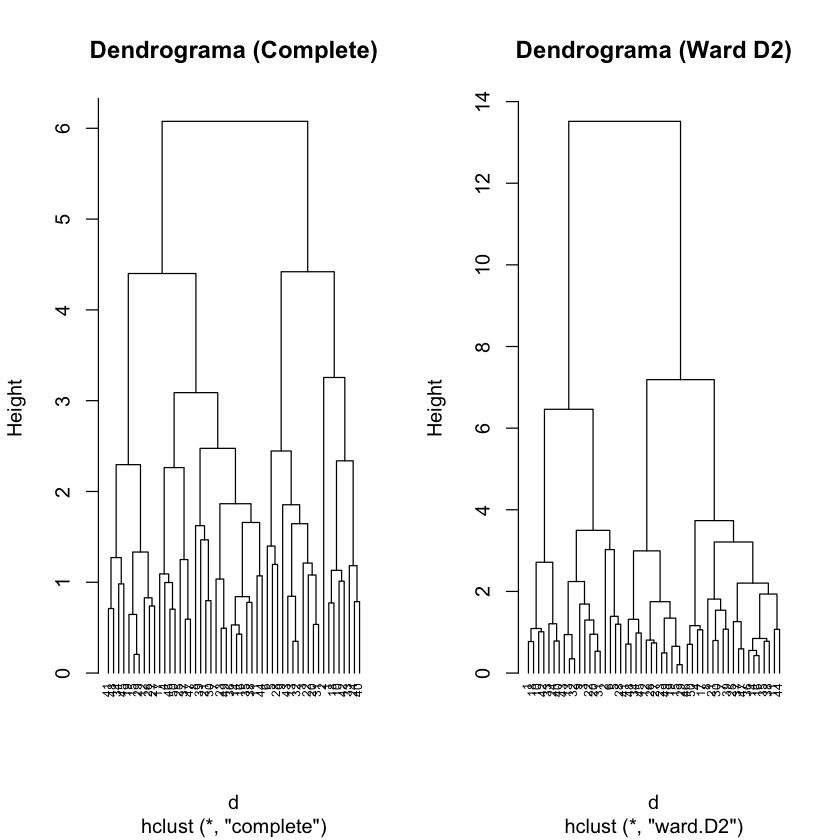

In [9]:
# Graficar dendrogramas
par(mfrow = c(1, 2))
plot(hc_complete, main = "Dendrograma (Complete)", cex = 0.6, hang = -1)
plot(hc_ward,    main = "Dendrograma (Ward D2)",    cex = 0.6, hang = -1)

In [10]:
# Elegir número de clusters y cortar árbol
k <- 4
clusters <- cutree(hc_ward, k = k)

In [11]:
# Ver cuántos elementos en cada clúster
table(clusters)

clusters
 1  2  3  4 
 7 12 19 12 

In [12]:
# Sumarizar características promedio por clúster
aggregate(df, by = list(cluster = clusters), FUN = mean)

cluster,Murder,Assault,UrbanPop,Rape
<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,14.671429,251.2857,54.28571,21.68571
2,10.966667,264.0000,76.50000,33.60833
3,6.210526,142.0526,71.26316,19.18421
4,3.091667,76.0000,52.08333,11.83333
